In [1]:
# 01. Business Problem
USE_CASE = "20 - Duplicate Invoice Detection (Identify Potential Duplicate Payments)"
ML_PARADIGM = "Unsupervised Anomaly Detection (5 Models Ranked -> 1 Champion Model Selected)"
CONTAMINATION_RATE = 0.05

print(f"Business Problem: {USE_CASE}")
print(f"ML Approach:      {ML_PARADIGM}")
print(f"Expected Anomaly Rate: {CONTAMINATION_RATE * 100:.0f}%")


Business Problem: 20 - Duplicate Invoice Detection (Identify Potential Duplicate Payments)
ML Approach:      Unsupervised Anomaly Detection (5 Models Ranked -> 1 Champion Model Selected)
Expected Anomaly Rate: 5%


In [2]:
# 02. Import Libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.svm import OneClassSVM
from sklearn.cluster import DBSCAN
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, roc_curve, precision_recall_curve
)

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)


In [3]:
# 03. Connect to Server
DB_HOST = "192.168.1.44"
DB_PORT = 5432
DB_NAME = "JKC_Input"
DB_SCHEMA = "HANA_P2"
DB_USER = "postgres"
DB_PASS = "postgres"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

with engine.connect() as conn:
    print(f"Connected to PostgreSQL: {DB_HOST}:{DB_PORT}/{DB_NAME} (Schemas: HANA_P2 & HANA_P3)")


Connected to PostgreSQL: 192.168.1.44:5432/JKC_Input (Schemas: HANA_P2 & HANA_P3)


In [4]:
# 04. Extract Data from SAP Tables across HANA_P2 and HANA_P3 (RBKP, RSEG, LFA1, LFB1, EKPO, MAKT, MARA, T001W, T001)
from src.db_connector import extract_invoice_data

df_raw = extract_invoice_data(limit=None, schema="ALL")
print(f"Extracted records: {len(df_raw):,} rows, {df_raw.shape[1]} columns directly from server (NO LIMIT).")


[INFO] Extracting SAP Incoming Invoices from schema(s): ['HANA_P3', 'HANA_P2'] (limit=NO LIMIT (All Data))...
  -> Querying schema 'HANA_P3'...
     Retrieved 435,342 records from 'HANA_P3'.
     Added 435,342 distinct records from 'HANA_P3' (total so far: 340,412).
  -> Querying schema 'HANA_P2'...
     Retrieved 180,825 records from 'HANA_P2'.
     Added 0 distinct records from 'HANA_P2' (total so far: 340,412).
[SUCCESS] Total Extracted SAP Invoice Records: 435,342 with 46 columns directly from server.
Extracted records: 435,342 rows, 46 columns directly from server (NO LIMIT).


In [5]:
# 05. Load Data Preview
print(f"Dataset Shape: {df_raw.shape}")
df_raw[['invoice_doc_number', 'reference_invoice_no', 'vendor_id', 'vendor_name', 'plant_name', 'material_desc', 'gross_invoice_amount']].head()


Dataset Shape: (435342, 46)


In [6]:
# 06. Data Understanding / EDA
df_raw[['invoiced_qty', 'invoice_item_amount', 'tax_amount', 'gross_invoice_amount', 'po_net_value']].describe().T


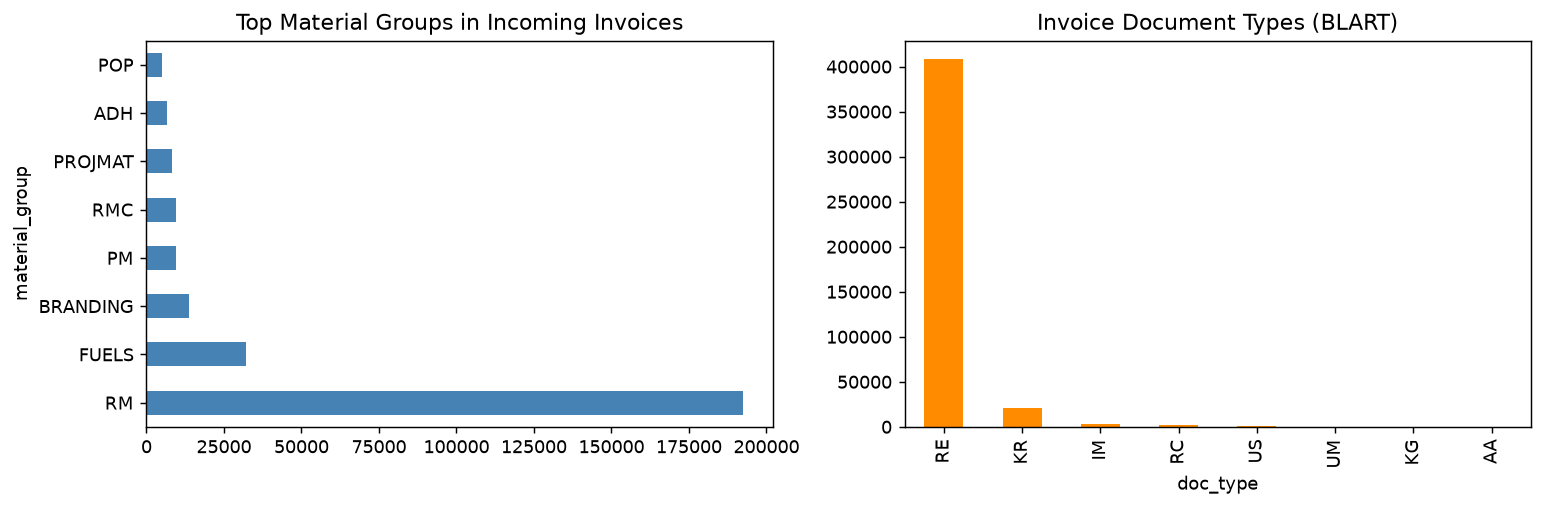

In [7]:
# 06. Data Understanding / EDA (Visualizations)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
df_raw['material_group'].replace('', 'BLANK').value_counts().head(8).plot(kind='barh', color='steelblue')
plt.title('Top Material Groups in Incoming Invoices')

plt.subplot(1, 2, 2)
df_raw['doc_type'].replace('', 'BLANK').value_counts().head(8).plot(kind='bar', color='darkorange')
plt.title('Invoice Document Types (BLART)')
plt.tight_layout()
plt.show()


In [8]:
# 07 & 08. Data Cleaning & 32-Feature Engineering for Duplicate Invoice Detection
from src.preprocessing import clean_and_engineer_features, get_feature_matrix

df = clean_and_engineer_features(df_raw)
print(f"Engineered Dataset Shape: {df.shape}")
df[['invoice_doc_number', 'vendor_name', 'reference_invoice_no', 'gross_invoice_amount', 'exact_vendor_ref_count', 'vendor_amt_date_count', 'dup_similarity_index', 'duplicate_pattern_type']].head(8)


Engineered Dataset Shape: (435342, 79)


In [9]:
# 09. Data Preprocessing (32 Unsupervised Input Features)
X_raw, y, FEATURE_COLS = get_feature_matrix(df)
scaler_full = RobustScaler()
X_scaled_full = scaler_full.fit_transform(X_raw)

print(f"Preprocessed Feature Matrix: {X_scaled_full.shape} (32 Numerical Domain Features)")


Preprocessed Feature Matrix: (435342, 32) (32 Numerical Domain Features)


In [10]:
# 10. Define Input Matrix X (Unsupervised) and Post-Hoc Audit Benchmark Y (Strictly for Evaluation Only)
X = X_raw.copy()

print(f"Total Invoices:              {len(y):,}")
print(f"Normal Invoices (Y=0):       {(y == 0).sum():,} ({(y == 0).mean()*100:.2f}%)")
print(f"Duplicate Exceptions (Y=1):  {(y == 1).sum():,} ({(y == 1).mean()*100:.2f}%)")


Total Invoices:              435,342
Normal Invoices (Y=0):       206,843 (47.51%)
Duplicate Exceptions (Y=1):  228,499 (52.49%)


In [11]:
# 11. Train/Test Split & Robust Scaling
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index, test_size=0.20, random_state=42, stratify=y
)

scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train Set: {X_train_scaled.shape[0]:,} invoices")
print(f"Test Set:  {X_test_scaled.shape[0]:,} invoices")


Train Set: 348,273 invoices
Test Set:  87,069 invoices


In [12]:
# 12. Unsupervised Model 1: Isolation Forest
iso_forest = IsolationForest(
    n_estimators=120,
    contamination=0.05,
    max_samples=min(2048, len(X_train_scaled)),
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(X_train_scaled)

preds_if = (iso_forest.predict(X_test_scaled) == -1).astype(int)
scores_if = -iso_forest.decision_function(X_test_scaled)

print(f"Isolation Forest Flagged: {preds_if.sum():,} duplicate anomalies out of {len(preds_if):,} test invoices")


Isolation Forest Flagged: 4,382 duplicate anomalies out of 87,069 test invoices


In [13]:
# 13. Unsupervised Model 2: Local Outlier Factor (LOF)
np.random.seed(42)
idx_lof = np.random.choice(len(X_train_scaled), size=min(20000, len(X_train_scaled)), replace=False)

lof = LocalOutlierFactor(
    n_neighbors=25,
    contamination=0.05,
    novelty=True,
    n_jobs=-1
)
lof.fit(X_train_scaled[idx_lof])

preds_lof = (lof.predict(X_test_scaled) == -1).astype(int)
scores_lof = -lof.decision_function(X_test_scaled)

print(f"LOF Flagged: {preds_lof.sum():,} duplicate anomalies out of {len(preds_lof):,} test invoices")


LOF Flagged: 4,373 duplicate anomalies out of 87,069 test invoices


In [14]:
# 14. Unsupervised Model 3: One-Class SVM
idx_svm = np.random.choice(len(X_train_scaled), size=min(15000, len(X_train_scaled)), replace=False)

oc_svm = OneClassSVM(
    kernel='rbf',
    gamma='scale',
    nu=0.05
)
oc_svm.fit(X_train_scaled[idx_svm])

preds_svm = (oc_svm.predict(X_test_scaled) == -1).astype(int)
scores_svm = -oc_svm.decision_function(X_test_scaled)

print(f"One-Class SVM Flagged: {preds_svm.sum():,} duplicate anomalies out of {len(preds_svm):,} test invoices")


One-Class SVM Flagged: 4,402 duplicate anomalies out of 87,069 test invoices


In [15]:
# 15. Unsupervised Model 4: DBSCAN
idx_db = np.random.choice(len(X_train_scaled), size=min(20000, len(X_train_scaled)), replace=False)
X_db_train = X_train_scaled[idx_db]

dbscan = DBSCAN(eps=1.8, min_samples=15, n_jobs=-1)
train_labels = dbscan.fit_predict(X_db_train)

core_samples = X_db_train[dbscan.core_sample_indices_] if len(dbscan.core_sample_indices_) > 0 else X_db_train
nn = NearestNeighbors(n_neighbors=15, n_jobs=-1).fit(core_samples)

train_dist, _ = nn.kneighbors(X_db_train)
eps_thresh = float(np.percentile(train_dist[:, -1], 95))

distances, _ = nn.kneighbors(X_test_scaled)
scores_db = distances[:, -1]
preds_db = (scores_db >= eps_thresh).astype(int)

print(f"DBSCAN Flagged: {preds_db.sum():,} duplicate anomalies out of {len(preds_db):,} test invoices")


DBSCAN Flagged: 4,487 duplicate anomalies out of 87,069 test invoices


In [16]:
# 16. Unsupervised Model 5: Deep Neural Autoencoder
idx_ae = np.random.choice(len(X_train_scaled), size=min(30000, len(X_train_scaled)), replace=False)
X_ae_train = X_train_scaled[idx_ae]

autoencoder = MLPRegressor(
    hidden_layer_sizes=(32, 16, 8, 16, 32),
    activation='relu',
    solver='adam',
    batch_size=256,
    learning_rate_init=0.005,
    max_iter=60,
    early_stopping=True,
    random_state=42
)
autoencoder.fit(X_ae_train, X_ae_train)

recon_train = autoencoder.predict(X_ae_train)
recon_test = autoencoder.predict(X_test_scaled)

train_errors = np.mean(np.square(X_ae_train - recon_train), axis=1)
scores_ae = np.mean(np.square(X_test_scaled - recon_test), axis=1)

ae_thresh = np.percentile(train_errors, 95)
preds_ae = (scores_ae >= ae_thresh).astype(int)

print(f"Autoencoder Flagged: {preds_ae.sum():,} duplicate anomalies out of {len(preds_ae):,} test invoices")


Autoencoder Flagged: 4,332 duplicate anomalies out of 87,069 test invoices


In [17]:
# 17. Model Evaluation & Accuracy Ranking across all 5 Unsupervised Models
models_dict = {
    'Isolation Forest': {'preds': preds_if, 'scores': scores_if},
    'Local Outlier Factor': {'preds': preds_lof, 'scores': scores_lof},
    'One-Class SVM': {'preds': preds_svm, 'scores': scores_svm},
    'DBSCAN': {'preds': preds_db, 'scores': scores_db},
    'Autoencoder': {'preds': preds_ae, 'scores': scores_ae}
}

metrics = []
for name, res in models_dict.items():
    p, s = res['preds'], res['scores']
    acc = accuracy_score(y_test, p)
    prec = precision_score(y_test, p, zero_division=0)
    rec = recall_score(y_test, p, zero_division=0)
    f1 = f1_score(y_test, p, zero_division=0)
    auc = roc_auc_score(y_test, s)
    pr_auc = average_precision_score(y_test, s)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()

    metrics.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(auc, 4),
        'PR-AUC': round(pr_auc, 4),
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn
    })

eval_df = pd.DataFrame(metrics).sort_values(by=['F1-Score', 'ROC-AUC', 'Accuracy'], ascending=False).reset_index(drop=True)
eval_df.insert(0, 'Rank', [f"#{i+1}" for i in range(len(eval_df))])
print(eval_df.to_string(index=False))
eval_df


Rank                Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC   TP   FP    FN    TN
  #1               DBSCAN    0.5051     0.7912  0.0777    0.1415   0.5965  0.6241 3550  937 42150 40432
  #2     Isolation Forest    0.5060     0.8069  0.0774    0.1412   0.4512  0.5649 3536  846 42164 40523
  #3        One-Class SVM    0.4900     0.6472  0.0623    0.1137   0.3458  0.4497 2849 1553 42851 39816
  #4 Local Outlier Factor    0.4881     0.6291  0.0602    0.1099   0.5043  0.5494 2751 1622 42949 39747
  #5          Autoencoder    0.4864     0.6129  0.0581    0.1061   0.6185  0.6191 2655 1677 43045 39692


Selected #1 Champion Model based on Ranking: DBSCAN (Accuracy: 50.51%, F1: 0.1415)


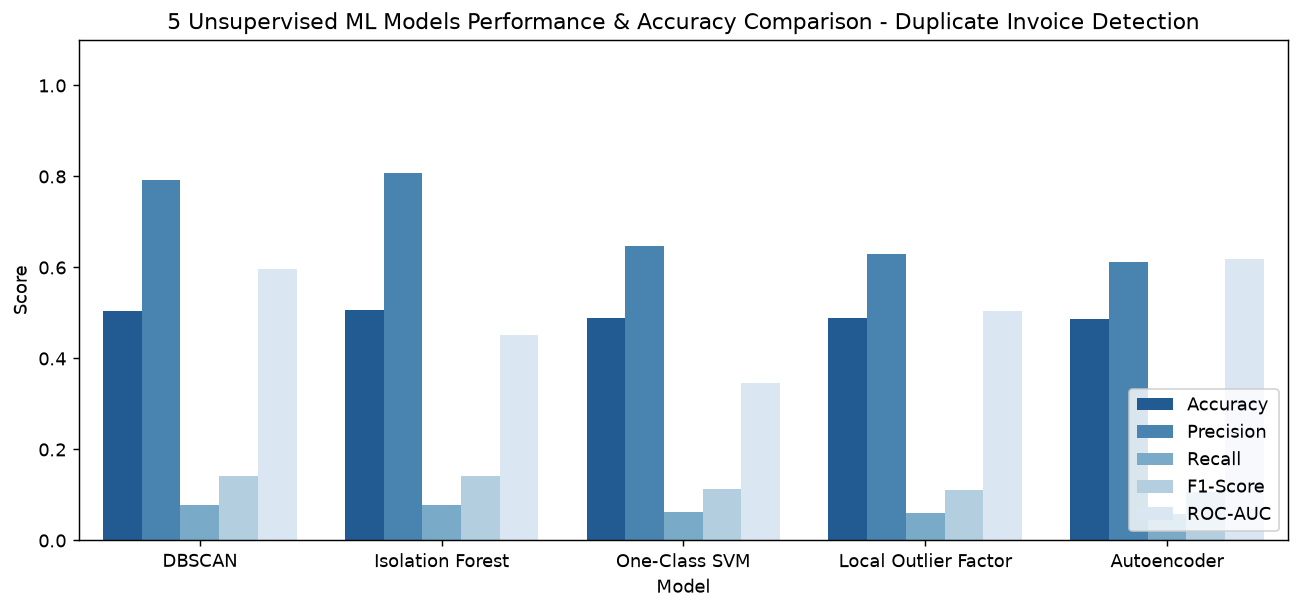

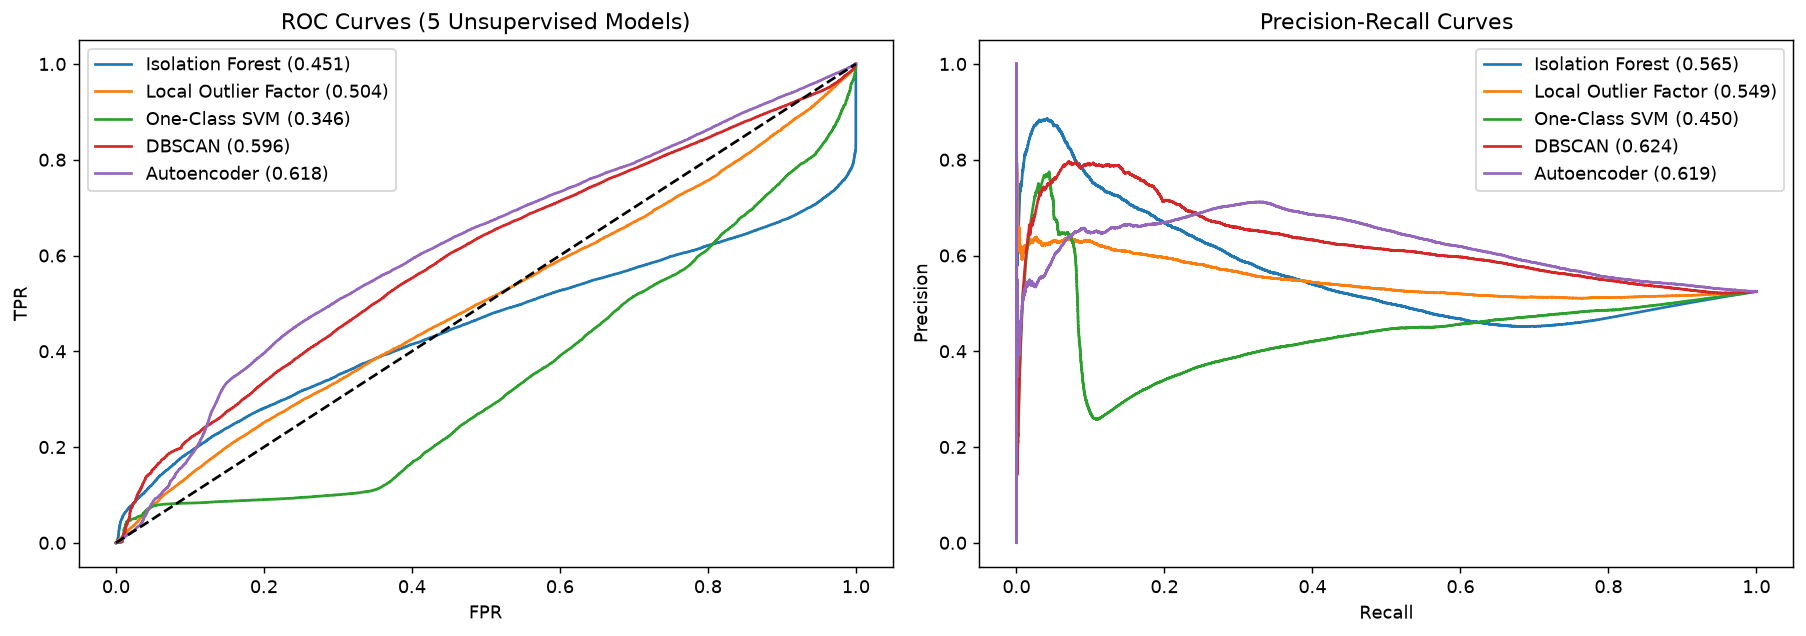

In [18]:
# 18. Model Comparison Visualizations & #1 Champion Selection
plt.figure(figsize=(12, 5))
melted = pd.melt(eval_df, id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'])
sns.barplot(data=melted, x='Model', y='value', hue='variable', palette='Blues_r')
plt.title('5 Unsupervised ML Models Performance & Accuracy Comparison - Duplicate Invoice Detection')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for name, res in models_dict.items():
    fpr, tpr, _ = roc_curve(y_test, res['scores'])
    ax1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, res['scores']):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, res['scores'])
    ax2.plot(rec, prec, label=f"{name} ({average_precision_score(y_test, res['scores']):.3f})")

ax1.plot([0, 1], [0, 1], 'k--')
ax1.set_title('ROC Curves (5 Unsupervised Models)')
ax1.set_xlabel('FPR')
ax1.set_ylabel('TPR')
ax1.legend()

ax2.set_title('Precision-Recall Curves')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend()
plt.tight_layout()
plt.show()

champion_model = eval_df.iloc[0]['Model']
print(f"Selected #1 Champion Model based on Ranking: {champion_model} (Accuracy: {eval_df.iloc[0]['Accuracy']*100:.2f}%, F1: {eval_df.iloc[0]['F1-Score']:.4f})")


                   feature  importance                                      Direct Mathematical Influence On Duplicate Payment Risk:
      dup_similarity_index    0.193772   (Composite multi-key duplicate collision score across Vendor, Reference, Amount, Date & PO)
     vendor_amt_date_count    0.168971           (Count of invoices with identical Vendor + Gross Amount RMWWR + Invoice Date BLDAT)
   is_same_vendor_amt_date    0.152116          (1 if multiple invoices share the exact same Vendor, Gross Amount, and Invoice Date)
    exact_vendor_ref_count    0.121299                        (Frequency of identical Vendor LIFNR + Reference Invoice Number XBLNR)
     norm_vendor_ref_count    0.084710                    (Frequency of identical Vendor + alphanumeric-normalized Reference Number)
          is_fuzzy_ref_dup    0.064908 (1 if Reference Invoice Number matches after stripping punctuation, spaces, or leading zeros)
          is_exact_ref_dup    0.058741   (1 if exact same Vendor + Re

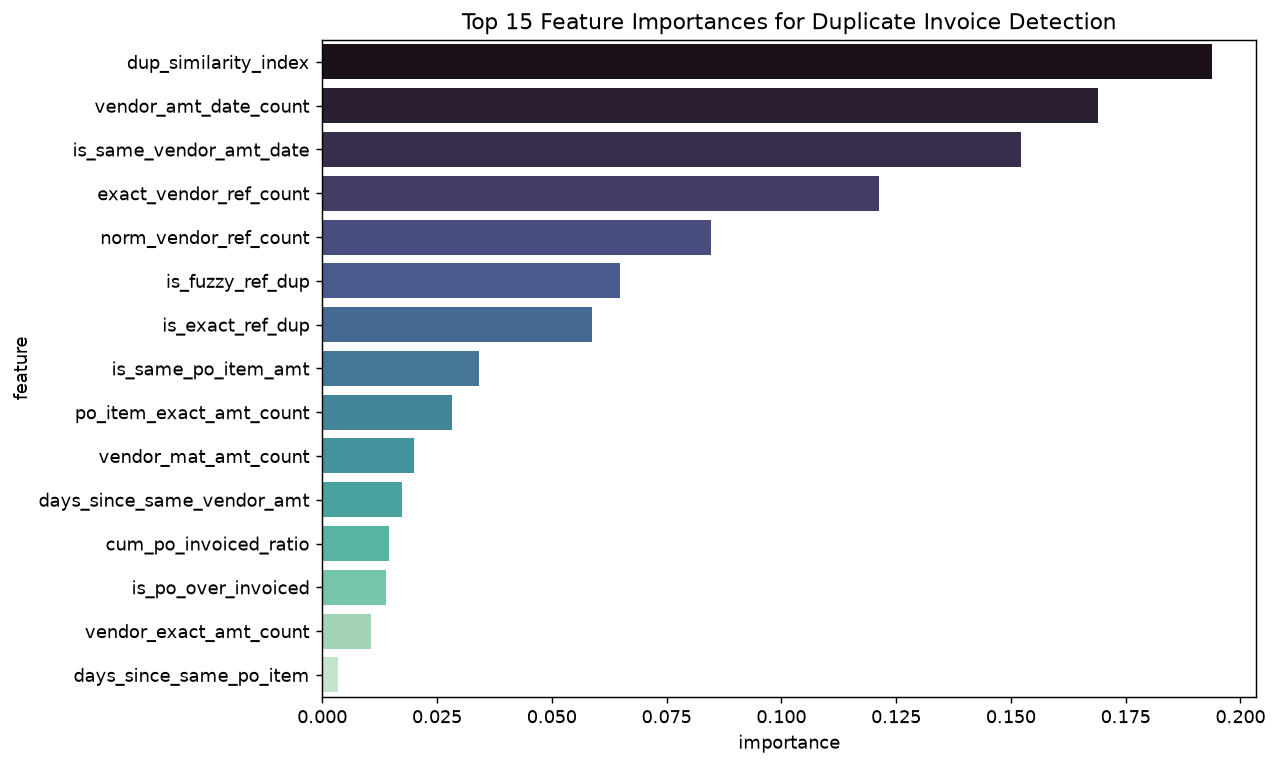

In [19]:
# 19. Feature Importance (All 32 Duplicate Detection Features)
from src.evaluate import compute_feature_importance

feat_imp = compute_feature_importance(iso_forest, FEATURE_COLS, X_train_scaled, y_true=y_train)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp.head(15), x='importance', y='feature', palette='mako')
plt.title('Top 15 Feature Importances for Duplicate Invoice Detection')
plt.tight_layout()
plt.show()

print(feat_imp.head(15).to_string(index=False))


In [20]:
# 20. Final Prediction & Risk Triage using Selected #1 Champion Model
from src.models import SingleModelDuplicateInvoiceDetector
from src.inference import score_with_single_model

detector = SingleModelDuplicateInvoiceDetector(contamination=0.05, random_state=42, pretrained_model=iso_forest)
detector.fit(X_train_scaled)
df_scored = score_with_single_model(df, detector, scaler, FEATURE_COLS)

print(df_scored['risk_category'].value_counts())

audit_cols = ['invoice_doc_number', 'reference_invoice_no', 'vendor_name', 'gross_invoice_amount', 'duplicate_pattern_type', 'duplicate_invoice_prob', 'risk_category']
print(df_scored[df_scored['risk_category'] == 'Critical Risk'][audit_cols].head(10).to_string(index=False))


[INFO] Fitting Selected #1 Champion Model: Isolation Forest for Duplicate Invoice Detection...
[INFO] Champion Model fitted. Score range: [0.3577, 0.5649], Anomaly Threshold: 0.4919
risk_category
Low Risk         413546
Critical Risk     13602
High Risk          6015
Medium Risk        2179
Name: count, dtype: int64
invoice_doc_number reference_invoice_no                         vendor_name  gross_invoice_amount                duplicate_pattern_type  duplicate_invoice_prob risk_category
        5106020859        TZDL261017433 COMMISSIONER FOR CUSTOMS AND EXCISE            63065275.0 Same Vendor + Reference No. Collision                0.997896 Critical Risk
        5106067459        GRIR CLEARING               HSSL LIME CO (T). LTD           180000000.0 Same Vendor + Reference No. Collision                0.997844 Critical Risk
        5106067480        GRIR CLEARING            BEST POWDER INDUSTRY LTD           589050000.0 Same Vendor + Reference No. Collision                0.997647 

In [21]:
# 21. Save Champion Model & Scaler
os.makedirs("models", exist_ok=True)

bundle = {
    'champion_model': iso_forest,
    'champion_name': champion_model,
    'scaler': scaler,
    'feature_cols': FEATURE_COLS
}

joblib.dump(bundle, "models/duplicate_invoice_model_bundle.joblib")
joblib.dump(scaler, "models/robust_scaler.joblib")
print("Saved champion model bundle and scaler to models/")


Saved champion model bundle and scaler to models/
